Dataset loaded successfully!

First 5 rows:


,study_hours,attendance,previous_score,assignments_completed,final_score
0,2,65,48,5,51
1,3,70,52,6,56
2,4,72,55,7,60
3,5,75,58,7,64
4,6,78,62,8,68



Dataset shape:
(67, 5)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 67 entries, 0 to 66
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   study_hours            67 non-null     int64
 1   attendance             67 non-null     int64
 2   previous_score         67 non-null     int64
 3   assignments_completed  67 non-null     int64
 4   final_score            67 non-null     int64
dtypes: int64(5)
memory usage: 2.7 KB
None

Missing values:
study_hours              0
attendance               0
previous_score           0
assignments_completed    0
final_score              0
dtype: int64

Statistical summary:


,study_hours,attendance,previous_score,assignments_completed,final_score
count,67.000000,67.000000,67.000000,67.000000,67.000000
mean,5.701493,78.955224,62.925373,7.626866,69.208955
std,2.790758,9.955100,11.323499,1.799291,13.459859
min,1.000000,58.000000,42.000000,4.000000,44.000000
25%,3.000000,72.000000,54.500000,6.000000,58.000000
50%,6.000000,80.000000,63.000000,8.000000,70.000000
75%,8.000000,87.000000,71.500000,9.000000,80.000000
max,10.000000,96.000000,85.000000,10.000000,94.000000


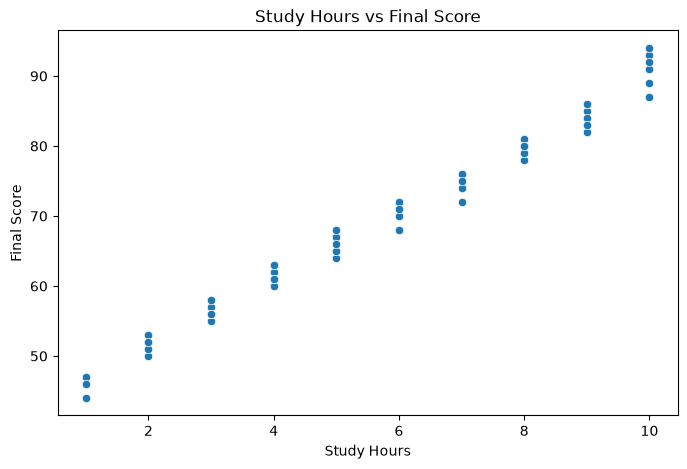

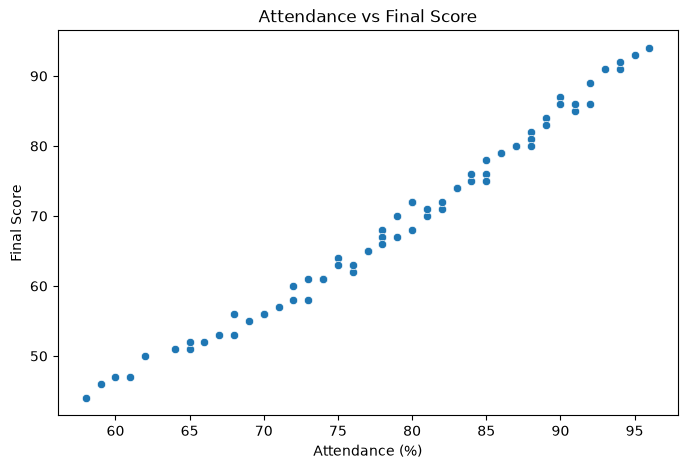

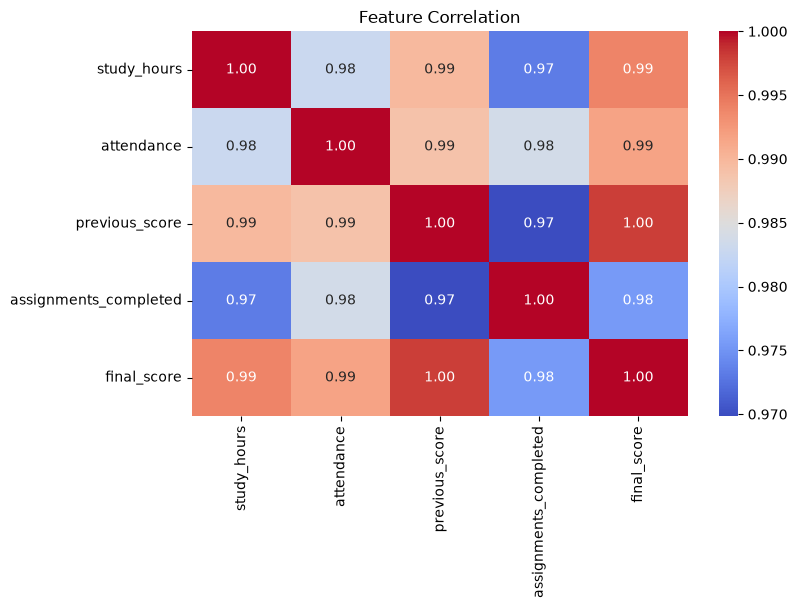

Training samples: 53
Testing samples: 14

Model trained successfully!

Prediction Results:


,Actual Score,Predicted Score
0,86,85.44
1,80,80.10
2,68,68.70
3,47,46.92
4,80,80.10
5,58,58.89
6,66,65.33
7,72,72.49
8,80,78.90
9,62,62.32



MODEL PERFORMANCE
----------------------------
Mean Absolute Error : 0.47
Mean Squared Error  : 0.32
Root Mean Square Error : 0.57
R² Score            : 1.00


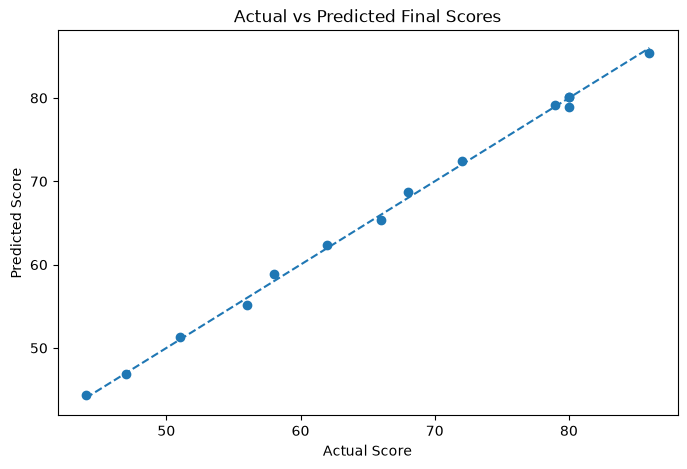


NEW STUDENT PREDICTION
----------------------------
Study Hours: 7
Attendance: 85%
Previous Score: 70
Assignments Completed: 9

Predicted Final Score: 77.01
Performance Category: Good

PROJECT COMPLETED SUCCESSFULLY!


In [7]:
# ============================================
# STUDENT PERFORMANCE PREDICTION
# Machine Learning Project
# ============================================

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ============================================
# 1. LOAD DATASET
# ============================================

data = pd.read_csv("../data/student_data.csv")

print("Dataset loaded successfully!")
print("\nFirst 5 rows:")
display(data.head())

print("\nDataset shape:")
print(data.shape)

# ============================================
# 2. CHECK DATA
# ============================================

print("\nDataset information:")
print(data.info())

print("\nMissing values:")
print(data.isnull().sum())

print("\nStatistical summary:")
display(data.describe())

# ============================================
# 3. DATA VISUALIZATION
# ============================================

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=data,
    x="study_hours",
    y="final_score"
)

plt.title("Study Hours vs Final Score")
plt.xlabel("Study Hours")
plt.ylabel("Final Score")
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=data,
    x="attendance",
    y="final_score"
)

plt.title("Attendance vs Final Score")
plt.xlabel("Attendance (%)")
plt.ylabel("Final Score")
plt.show()

plt.figure(figsize=(8, 5))
sns.heatmap(
    data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation")
plt.show()

# ============================================
# 4. PREPARE DATA
# ============================================

X = data[
    [
        "study_hours",
        "attendance",
        "previous_score",
        "assignments_completed"
    ]
]

y = data["final_score"]

# ============================================
# 5. SPLIT DATASET
# ============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# ============================================
# 6. TRAIN MACHINE LEARNING MODEL
# ============================================

model = LinearRegression()

model.fit(X_train, y_train)

print("\nModel trained successfully!")

# ============================================
# 7. MAKE PREDICTIONS
# ============================================

y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Score": y_test.values,
    "Predicted Score": np.round(y_pred, 2)
})

print("\nPrediction Results:")
display(results)

# ============================================
# 8. MODEL EVALUATION
# ============================================

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nMODEL PERFORMANCE")
print("----------------------------")
print(f"Mean Absolute Error : {mae:.2f}")
print(f"Mean Squared Error  : {mse:.2f}")
print(f"Root Mean Square Error : {rmse:.2f}")
print(f"R² Score            : {r2:.2f}")

# ============================================
# 9. ACTUAL VS PREDICTED GRAPH
# ============================================

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Actual vs Predicted Final Scores")
plt.xlabel("Actual Score")
plt.ylabel("Predicted Score")

plt.show()

# ============================================
# 10. PREDICT PERFORMANCE OF A NEW STUDENT
# ============================================

new_student = pd.DataFrame({
    "study_hours": [7],
    "attendance": [85],
    "previous_score": [70],
    "assignments_completed": [9]
})

prediction = model.predict(new_student)[0]

print("\nNEW STUDENT PREDICTION")
print("----------------------------")
print(f"Study Hours: 7")
print(f"Attendance: 85%")
print(f"Previous Score: 70")
print(f"Assignments Completed: 9")
print(f"\nPredicted Final Score: {prediction:.2f}")

# ============================================
# 11. PERFORMANCE CATEGORY
# ============================================

if prediction >= 85:
    category = "Excellent"
elif prediction >= 70:
    category = "Good"
elif prediction >= 50:
    category = "Average"
else:
    category = "Needs Improvement"

print(f"Performance Category: {category}")

print("\n============================================")
print("PROJECT COMPLETED SUCCESSFULLY!")
print("============================================")